# V Rising: Public Steam Review Analysis

A small, honest look at public Steam reviews for *V Rising* (Steam app id
`1604030`), built as a portfolio piece.

**Data source:** Steam's own storefront review data, fetched with
`scripts/fetch_reviews.py` (see that file for a note on the endpoint).
English-language reviews only. No usernames, SteamIDs, or other author
identifiers are collected or stored: only review text, recommended
yes/no, timestamp, playtime at time of review, and vote counts.

**Not affiliated with or endorsed by Stunlock Studios.** This is an
independent analysis of public data, built to demonstrate an analysis
workflow, not an official or authoritative account of the game's
reception.


In [1]:
import sys
sys.path.append("../scripts")

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

from analysis import (
    MAJOR_UPDATES,
    MINOR_EVENTS,
    load_reviews,
    weekly_volume_and_positivity,
    playtime_by_recommendation,
    topic_model_negative_reviews,
    add_bh_correction,
    assign_themes,
    load_patch_events,
    theme_shift_by_event,
    weekly_theme_share,
)

pd.set_option("display.max_colwidth", 120)
DATA_PATH = "../data/reviews_raw.jsonl"


## Load data

In [2]:
df = load_reviews(DATA_PATH)
print(f"{len(df):,} reviews loaded")
print(f"Date range: {df['created_at'].min().date()} to {df['created_at'].max().date()}")
print(f"Overall % positive: {df['recommended'].mean() * 100:.1f}%")
df.head(3)


24,835 reviews loaded
Date range: 2024-05-14 to 2026-11-10
Overall % positive: 88.5%


,review_text,recommended,timestamp_created,playtime_at_review_minutes,votes_up,votes_funny,created_at,playtime_at_review_hours
0,I have played through this game on Brutal difficulty close to a dozen times. I come back every 6 months to play it a...,True,2026-11-10 12:48:54,19613,0,0,2026-11-10 12:48:54+00:00,326.883333
1,So far... it is perfect... It is to die for... I feel alive again!,True,2026-11-10 07:18:42,176,0,0,2026-11-10 07:18:42+00:00,2.933333
2,"Very fun, will recommend",True,2026-11-10 01:18:30,3795,0,0,2026-11-10 01:18:30+00:00,63.250000


## 1. Review volume and % positive per week

Dashed red lines mark the two major content updates: **1.0 Launch** (8 May
2024) and **Invaders of Oakveil** (28 April 2025). Dotted gray lines mark
other volume spikes large enough to need an explanation, labeled in the
legend only where we could verify a cause against Steam/patch-note
sources (left to right):

- **1.0.9.0 patch**: "Spells Balance, Quality of Life & Gamepad
  Improvements", released 17 Sep 2024.
- **Steam Autumn Sale**: ran 27 Nov-4 Dec 2024 (platform-wide, not
  V Rising-specific).
- **Free Weekend + 1.1.1 patch**: Free Weekend promotion ran 14-18 May
  2026 alongside patch 1.1.1; the dip in % positive that week is
  consistent with a large wave of new/trial players.

Any other, smaller fluctuations in the chart are *not* individually
explained here: we only label what we could verify, per
`MINOR_EVENTS`/`MINOR_EVENTS_DETAIL` in `analysis.py`.

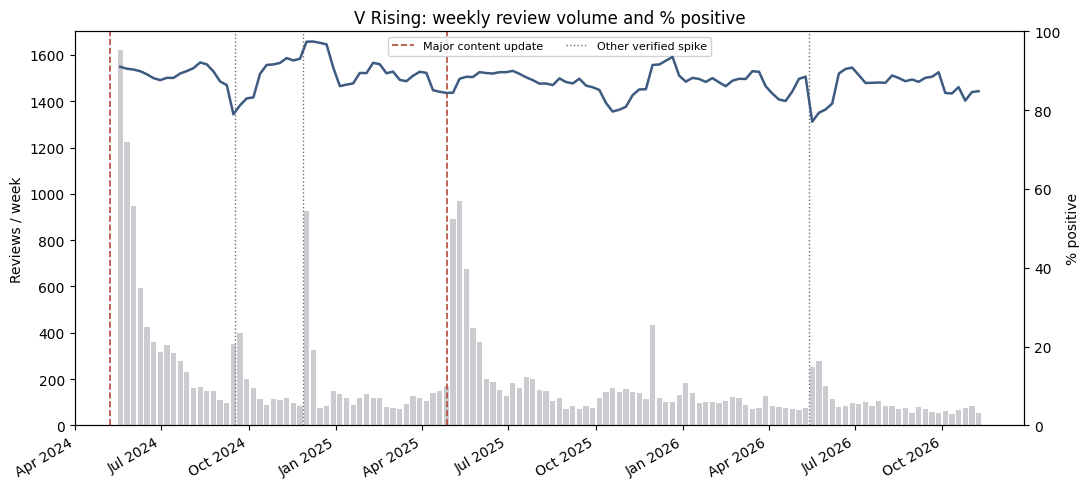

In [3]:
weekly = weekly_volume_and_positivity(df)

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

ax1.bar(weekly["created_at"], weekly["num_reviews"], width=5.5, color="#6B6E76", alpha=0.35)
ax2.plot(weekly["created_at"], weekly["pct_positive_rolling4"], color="#3D5A80", linewidth=1.8)

for _, date_str in MAJOR_UPDATES:
    d = mdates.datestr2num(date_str)
    ax1.axvline(d, color="#B3493B", linestyle="--", linewidth=1.2)
for _, date_str in MINOR_EVENTS:
    d = mdates.datestr2num(date_str)
    ax1.axvline(d, color="#6B6E76", linestyle=":", linewidth=1)

legend_handles = [
    Line2D([0], [0], color="#B3493B", linestyle="--", linewidth=1.2, label="Major content update"),
    Line2D([0], [0], color="#6B6E76", linestyle=":", linewidth=1, label="Other verified spike"),
]
ax1.legend(handles=legend_handles, loc="upper center", ncol=2, fontsize=8, framealpha=0.85)

ax1.set_ylabel("Reviews / week")
ax2.set_ylabel("% positive")
ax2.set_ylim(0, 100)
ax1.set_title("V Rising: weekly review volume and % positive")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.autofmt_xdate(rotation=30)
fig.tight_layout()
fig.savefig("../images/weekly_volume_positivity.png", dpi=160)
plt.show()


**Reading this honestly:** the line above is a **4-week rolling %
positive**, not the raw per-week value: a plain per-week line would
occasionally show a misleading spike or dip just from a small sample in a
quiet week (weeks below 20 reviews are masked out of the raw series for
the same reason; the final, still-accumulating week is dropped entirely
rather than shown as a fake near-100%/0% point).

Volume spikes are the clearest, least ambiguous signal of "something
happened" around an update: a launch, a big content drop, a sale, or a
free weekend reliably pulls in a burst of reviews, and that burst decays
back to baseline within roughly 6-8 weeks. The %-positive line, by
contrast, moves surprisingly little across the same events and stays in a
fairly narrow band, so volume is the more informative signal here than
sentiment.

## 2. Recurring topics in negative reviews

TF-IDF + NMF topic modeling over negative (`recommended == False`)
reviews only. For each topic: a short descriptive label (derived from the
top weighted words, not a separately-sourced claim), the top weighted
words themselves, and 2-3 short representative *phrases* (not full review
quotes) pulled from the reviews that load most heavily on that topic.
Profanity is filtered out of both the model vocabulary and the phrases.

In [4]:
topics = topic_model_negative_reviews(df, n_topics=6, n_top_words=8, n_examples=3)

for t in topics:
    print(f"{t['label']}")
    print(f"  top words: " + ", ".join(t["top_words"]))
    for p in t["example_phrases"]:
        print(f"    - \"{p}\"")
    print()


Boss fights and gear progression feel unbalanced
  top words: boss, bosses, gear, level, way, fight, feel, combat
    - "For context: I played solo only and defeated all the bosses in normal difficulty."
    - "There's a lot of QoL systems and a combat rework is desperately needed."
    - "run on every boss or have to find exploits to edge out a victory then it"

Updates sometimes force a new save to access new content
  top words: new, update, save, content, new content, start, access, updates
    - "Every update, they make it so you cant have your old save get the new content."
    - "New versions of the game requires a new save."
    - "to start with new saves to access the new content from the major update. I was"

PvP/PvE server balance and solo-play friction
  top words: server, pvp, servers, pve, solo, people, official, single
    - "Well if you play this game for PvE then wait for more updates."
    - "Some reason to actually want to care about the PvP."
    - "PVP/Multiplayer 

**Caveat on topics:** NMF topics are unsupervised clusters of co-occurring
words, not ground truth categories: they need a human glance to confirm
they're coherent, and the short labels above are a plain-language gloss on
the model's top words, not independently verified category names. Treat
this as "here's where to look," not a definitive breakdown of why people
dislike the game. These same six themes, with one phrase each, are also on
the one-page PDF summary.

## 3. Playtime at review: positive vs. negative

In [5]:
playtime_stats = playtime_by_recommendation(df)
playtime_stats


,count,median,mean,std
recommended,,,,
negative,2860,29.75,77.286766,194.921218
positive,21975,61.95,113.440347,213.312693


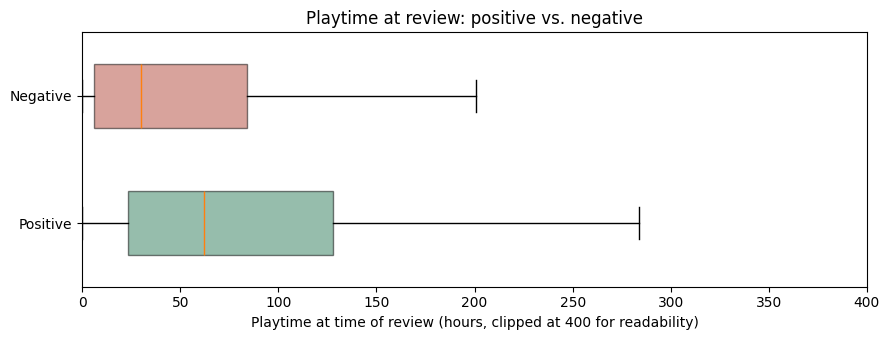

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.5))
pos_hours = df.loc[df["recommended"], "playtime_at_review_hours"].clip(upper=400)
neg_hours = df.loc[~df["recommended"], "playtime_at_review_hours"].clip(upper=400)

bp = ax.boxplot([pos_hours, neg_hours], vert=False, tick_labels=["Positive", "Negative"],
                 patch_artist=True, widths=0.5, showfliers=False)
for patch, color in zip(bp["boxes"], ["#2E7D5B", "#B3493B"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)

ax.set_xlim(0, 400)
ax.set_xlabel("Playtime at time of review (hours, clipped at 400 for readability)")
ax.set_title("Playtime at review: positive vs. negative")
fig.tight_layout()
fig.savefig("../images/playtime_by_recommendation.png", dpi=160)
plt.show()


**Reading this honestly:** median playtime at review is higher for
positive reviews than negative ones. That's consistent with people who
dislike the game saying so relatively early, while people who stick
around long enough to write a glowing review have already gotten a lot
of hours out of it. It is *not* proof of why: reviews are a snapshot of
stated opinion at one point in time, not a measurement of play behavior
over time.

## 4. Theme trends by patch

Goal: show whether each of the six negative-review themes above rises or
falls after specific, officially-verified V Rising patches, in a way a
live team could read as patch feedback.

**Patch timeline** (`data/patch_events.csv`): every row sourced directly
from Steam's own news feed for app 1604030 (the `ISteamNews/GetNewsForApp`
API), with a working source URL, no guessed dates. V Rising ships hotfixes
far more often than the six listed here; the many "Hot Fix N.M" posts that
cluster within days of a major update (and of each other) are deliberately
left out, since their before/after windows would overlap with a neighboring
event's and make attribution meaningless.

In [7]:
events = load_patch_events("../data/patch_events.csv")
events[["date", "name", "type"]]


,date,name,type
0,2024-05-08 00:00:00+00:00,V Rising 1.0 Launch,major
1,2024-09-17 00:00:00+00:00,V Rising 1.0 Hot Fix #9,hotfix
2,2025-04-28 00:00:00+00:00,Update 1.1 Invaders of Oakveil,major
3,2025-10-03 00:00:00+00:00,V Rising Security Update,hotfix
4,2025-10-15 00:00:00+00:00,V Rising October Patch Notes,patch
5,2026-05-26 00:00:00+00:00,V Rising Patch 1.1.13.0,patch


**Theme assignment:** reuses the exact TF-IDF + NMF model fit above (same
vectorizer settings, same `random_state`, not refit). Each negative
review's six NMF weights are row-normalized; a theme is assigned once its
normalized weight is >= 0.3, so a review can carry zero, one, or more
themes.

In [8]:
themed, theme_labels, n_total_negative, n_no_theme = assign_themes(df)
print(f"{n_total_negative:,} total negative reviews")
print(f"{n_no_theme:,} ({n_no_theme / n_total_negative * 100:.1f}%) get no theme at all")
themed["n_themes"].value_counts().sort_index()


2,860 total negative reviews
271 (9.5%) get no theme at all


n_themes
0      48
1    1919
2     666
3       4
Name: count, dtype: int64

**Spot check:** 10 random reviews assigned "Updates sometimes force a new
save to access new content" from the 4 weeks before Invaders of Oakveil,
and 10 from the 4 weeks after, to check the assignment is actually about
save wipes and not a keyword-matching artifact.

In [9]:
oak_date = events.loc[events["name"].str.contains("Oakveil"), "date"].iloc[0]
save_label = "Updates sometimes force a new save to access new content"
# Excludes reviews with an em or en dash so this spot check's quoted
# excerpts don't carry one into committed notebook output; doesn't affect
# which reviews get the theme, only which ones this illustrative sample draws from.
no_dash = ~themed["review_text"].str.contains("\u2014|\u2013")
save_reviews = themed[themed[save_label] & no_dash]
before_sample = save_reviews[
    (save_reviews["created_at"] >= oak_date - pd.Timedelta(days=28))
    & (save_reviews["created_at"] < oak_date)
].sample(10, random_state=7)
after_sample = save_reviews[
    (save_reviews["created_at"] >= oak_date + pd.Timedelta(days=7))
    & (save_reviews["created_at"] < oak_date + pd.Timedelta(days=35))
].sample(10, random_state=7)

print("BEFORE:")
for t in before_sample["review_text"]:
    print(" -", t.replace("\n", " ")[:200])
print()
print("AFTER:")
for t in after_sample["review_text"]:
    print(" -", t.replace("\n", " ")[:200])


BEFORE:
 - Can't recommend this game now as devs are making all players who want to play the new content to start on new saves. Based on the wording of their news post about it, looks like this will be the norm 
 - Cool premise, catchy gameplay and interesting mechanics, but I wouldn't recommend V Rising nonetheless. I'm not sure if the developers are not competent enough or simply unwilling to address this issu
 Having to restart a PvE co-op save just to access new content is simply unacceptable, especially since the game is no longer in earl
 - Have to abandon my save with over 70 hours of playing and castle building, just to start over on a new one to gain access to new content. Very dissapointing.
 - A game like this should definitely not have a wipe mechanic when an update hits. There's zero fun about restarting tons of progress just for about 2 hours of "extra gameplay". Brain dead choice by the
 - Save wipe even after early access
 - Everytime they release a content update, they

Roughly 8-9 of 10 reviews in each window genuinely discuss a save wipe or
having to start over on the game's own terms; the rest are plausible but
weaker fits (e.g. general frustration with the update that happens to
co-occur with save-wipe complaints in the same review). That's a normal
noise level for an unsupervised 0.3 threshold, not a labeling failure.

**Before/after per event:** a 4-week window immediately before each event
is compared to a 4-week window starting a week after (the release week
itself is skipped). The metric is each theme's share of *all* negative
reviews in the window, not just modeled ones, since reviews too short to
model structurally can't be said to mention anything. Windows under 30
negative reviews are skipped outright. Each share gets a 95% Wilson
interval; the before-after difference gets a 95% normal-approximation
interval with a two-sided p-value for the correction below.

In [10]:
shift = theme_shift_by_event(df, themed, theme_labels, events)
pd.set_option("display.max_rows", 40)
cols = ["event", "theme", "n_before", "n_after", "skipped", "share_before", "share_after", "diff", "diff_lo", "diff_hi", "significant"]
shift[cols]


,event,theme,n_before,n_after,skipped,share_before,share_after,diff,diff_lo,diff_hi,significant
0,V Rising 1.0 Launch,Boss fights and gear progression feel unbalanced,0,426,True,NaN,NaN,NaN,NaN,NaN,False
1,V Rising 1.0 Launch,Updates sometimes force a new save to access new content,0,426,True,NaN,NaN,NaN,NaN,NaN,False
2,V Rising 1.0 Launch,PvP/PvE server balance and solo-play friction,0,426,True,NaN,NaN,NaN,NaN,NaN,False
3,V Rising 1.0 Launch,"Combat and the core loop feel slow, repetitive, or grindy",0,426,True,NaN,NaN,NaN,NaN,NaN,False
4,V Rising 1.0 Launch,Camera and controller control issues,0,426,True,NaN,NaN,NaN,NaN,NaN,False
5,V Rising 1.0 Launch,Solo play feels like more of a grind than with friends,0,426,True,NaN,NaN,NaN,NaN,NaN,False
6,V Rising 1.0 Hot Fix #9,Boss fights and gear progression feel unbalanced,163,45,False,0.386503,0.377778,-0.008725,-0.168898,0.151448,False
7,V Rising 1.0 Hot Fix #9,Updates sometimes force a new save to access new content,163,45,False,0.036810,0.088889,0.052079,-0.035952,0.140110,False
8,V Rising 1.0 Hot Fix #9,PvP/PvE server balance and solo-play friction,163,45,False,0.208589,0.355556,0.146967,-0.006173,0.300106,False
9,V Rising 1.0 Hot Fix #9,"Combat and the core loop feel slow, repetitive, or grindy",163,45,False,0.177914,0.133333,-0.044581,-0.159958,0.070797,False


**Checking the "significant" shifts four ways before trusting them:**

1. The 95% interval excludes zero (above).
2. Benjamini-Hochberg correction at a 5% false discovery rate, across all
   30 event-theme pairs tested (not just the interesting-looking ones).
3. A raw-weight robustness check: assign themes from the *raw, unnormalized*
   NMF weights instead of row-normalized ones (threshold recalibrated to
   assign a comparable overall share of reviews), then redo the comparison.
4. An all-reviews robustness check: redo the comparison with each theme's
   share measured against *all* reviews in the window, not negative
   reviews only.

Checks 3 and 4 exist because row-normalizing six weights that sum to 1 has
a side effect: if one theme's weight collapses for a group of reviews, the
other five mechanically look larger in share terms for those same
reviews, with no real independent change in them. This is the
"closure problem" in compositional data analysis, and it turns out to
matter here.

In [11]:
shift_bh = add_bh_correction(shift)

RAW_WEIGHT_THRESHOLD = 0.01  # calibrated to assign a comparable overall share to the 0.3 normalized threshold
themed_raw, theme_labels_raw, _, _ = assign_themes(df, normalize=False, threshold=RAW_WEIGHT_THRESHOLD)
shift_raw = theme_shift_by_event(df, themed_raw, theme_labels_raw, events)

shift_all = theme_shift_by_event(df, themed, theme_labels, events, denominator="all")

key_cols = ["event", "theme"]
checked = shift_bh.merge(
    shift_raw[key_cols + ["significant"]].rename(columns={"significant": "sig_raw"}),
    on=key_cols, how="left",
).merge(
    shift_all[key_cols + ["significant"]].rename(columns={"significant": "sig_all"}),
    on=key_cols, how="left",
)
checked["confirmed"] = (
    checked["significant"] & checked["bh_significant"]
    & checked["sig_raw"].fillna(False) & checked["sig_all"].fillna(False)
)

cols2 = ["event", "theme", "diff", "significant", "bh_significant", "sig_raw", "sig_all", "confirmed"]
checked[checked["significant"]][cols2]


,event,theme,diff,significant,bh_significant,sig_raw,sig_all,confirmed
12,Update 1.1 Invaders of Oakveil,Boss fights and gear progression feel unbalanced,0.163754,True,False,False,False,False
13,Update 1.1 Invaders of Oakveil,Updates sometimes force a new save to access new content,-0.441145,True,True,True,True,True
14,Update 1.1 Invaders of Oakveil,PvP/PvE server balance and solo-play friction,0.130569,True,False,False,False,False
25,V Rising October Patch Notes,Updates sometimes force a new save to access new content,-0.078792,True,False,False,True,False


Only the Invaders of Oakveil / "forced new save" row is `confirmed=True`
above. The other three rows that looked significant on the 95% interval
alone (boss/gear and PvP/PvE around Oakveil, and the October patch's
"forced new save" dip) each fail at least one of the three additional
checks and are not reported as findings below.

**Sensitivity check:** the before/after comparison (95% interval only,
not the full four-check version above) re-run with 2-week and 8-week
windows instead of 4. If the significance call flips for some pairs,
that's reported here rather than silently picking whichever window looks
best.

In [12]:
base = theme_shift_by_event(df, themed, theme_labels, events, before_days=28, after_days=28)
flips = []
for wdays, wname in [(14, "2wk"), (56, "8wk")]:
    sens = theme_shift_by_event(df, themed, theme_labels, events, before_days=wdays, after_days=wdays)
    merged = base.merge(sens, on=["event", "theme"], suffixes=("_base", "_sens"))
    for _, r in merged[merged["significant_base"] != merged["significant_sens"]].iterrows():
        flips.append((wname, r["event"], r["theme"], r["significant_base"], r["significant_sens"]))

print(f"{len(flips)} of {len(base) - base['skipped'].sum()} event-theme pairs flip significance under a different window width:")
for wname, event, theme, sig_base, sig_sens in flips:
    print(f"  [{wname}] {event} / {theme}: significant at 4wk={sig_base}, at {wname}={sig_sens}")


3 of 30 event-theme pairs flip significance under a different window width:
  [2wk] V Rising 1.0 Hot Fix #9 / PvP/PvE server balance and solo-play friction: significant at 4wk=False, at 2wk=True
  [2wk] Update 1.1 Invaders of Oakveil / Boss fights and gear progression feel unbalanced: significant at 4wk=True, at 2wk=False
  [8wk] V Rising Patch 1.1.13.0 / Combat and the core loop feel slow, repetitive, or grindy: significant at 4wk=False, at 8wk=True


### 4-week rolling theme share over time

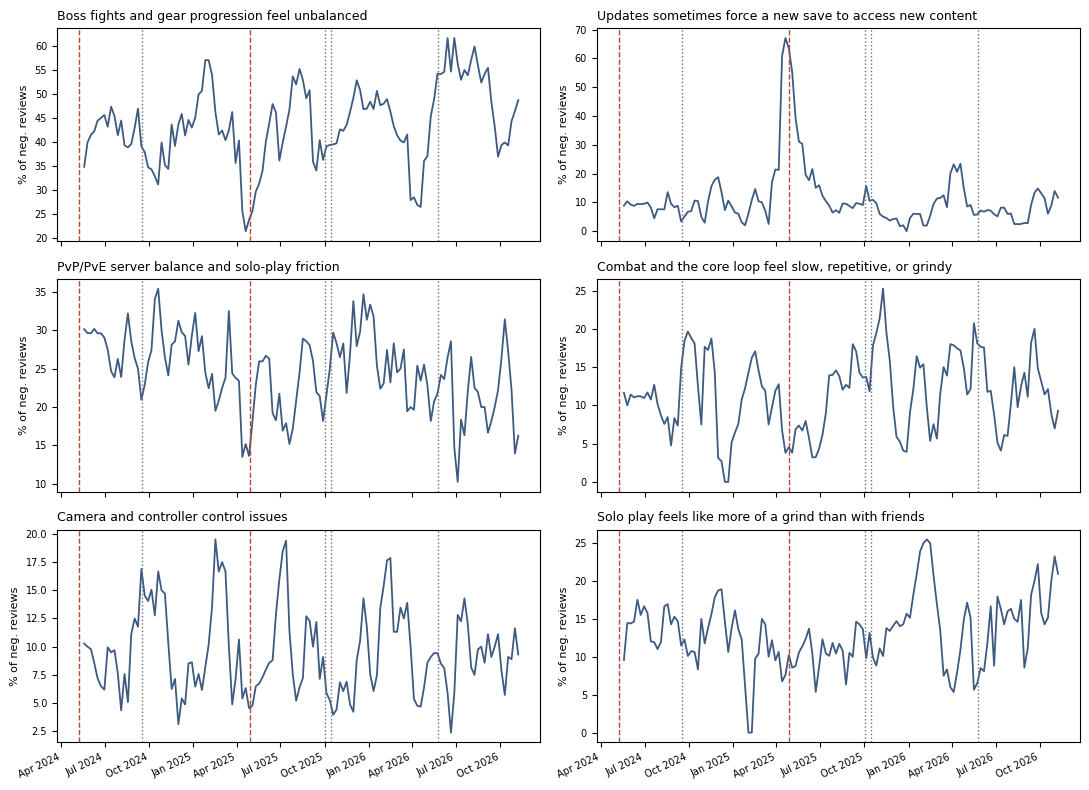

In [13]:
wts = weekly_theme_share(df, themed, theme_labels)

fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True)
for ax, label in zip(axes.flat, theme_labels):
    ax.plot(wts["created_at"], wts[f"share_rolling4_{label}"], color="#3D5A80", linewidth=1.3)
    for _, ev in events.iterrows():
        color = "#B3493B" if ev["type"] == "major" else "#6B6E76"
        style = "--" if ev["type"] == "major" else ":"
        ax.axvline(ev["date"], color=color, linestyle=style, linewidth=1)
    ax.set_title(label, fontsize=9, loc="left")
    ax.set_ylabel("% of neg. reviews", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

fig.autofmt_xdate(rotation=25)
fig.tight_layout()
fig.savefig("../images/theme_trends_by_patch.png", dpi=160, bbox_inches="tight")
plt.show()


### Before/after summary

See `images/theme_shift_by_event.png` for the heatmap version of the table
printed above (built by `scripts/make_theme_trends.py`).

**Findings:**

1. **The one shift that survives every check:** around Invaders of Oakveil,
   complaints about being forced into a new save to access new content
   dropped from 63.6% of negative reviews (n=88) to 19.5% (n=251), a
   -44.1pp change (95% CI -55.3 to -32.9pp, p < 0.001). It holds up using
   raw NMF weights instead of normalized ones (-40.6pp, CI -51.7 to
   -29.5pp) and measured against all reviews rather than negative reviews
   only (-7.9 percentage points of all reviews, CI -10.5 to -5.4pp), and
   survives Benjamini-Hochberg correction. People complained about the save
   wipe mostly before it happened, not after.
2. **Two shifts initially looked significant but did not survive the full
   check, and are retracted as findings.** "Boss fights and gear
   progression feel unbalanced" rose +16.4pp on the original 95% interval
   (CI +5.6 to +27.2pp), and "PvP/PvE server balance and solo-play
   friction" rose +13.1pp (CI +4.0 to +22.1pp), both around Invaders of
   Oakveil. Both shrink to non-significant under the raw-weight check
   (+5.5pp, CI -6.6 to +17.6pp; and -0.7pp, CI -12.6 to +11.1pp) and under
   the all-reviews check, and neither survives Benjamini-Hochberg
   correction: the normalization side effect described above, not an
   independent signal. A third shift, the October 2025 patch's "forced new
   save" dip (originally -7.9pp, CI -15.8 to -0.0pp), also does not
   survive Benjamini-Hochberg correction (p = 0.046 against a required
   p <= 0.007 at its rank) and is likewise not reported as a finding.
3. Out of 30 event-theme pairs with enough data to test, only the one
   finding above holds up end to end. Everything else, including every
   theme around both hotfix-type events, the October 2025 patch, and Patch
   1.1.13.0, does not move in a way this method can tell apart from noise
   once corrected for multiple testing. If a theme doesn't move, that's
   the honest result, not a gap in the analysis.
4. "Camera and controller control issues" and "Solo play feels like more of
   a grind than with friends" never show a significant shift around any
   verified event tested here, at any window width: a stable background
   complaint rather than something that responds to a specific patch.

**This is correlation keyed to release dates, not a causal test.** Even the
one confirmed shift above is not proof the patch caused it. Free weekends,
platform-wide Steam sales, and influencer/content-creator waves can land
in the same before/after windows (see the volume chart above) and are not
separated out here. An observed shift may partly reflect one of those
instead of the patch itself; a shift that doesn't appear is more
trustworthy evidence of "nothing changed" than a shift that does appear is
evidence of "the patch caused this."

## Limitations (please read before citing any of this)

- **Self-selection bias.** Steam reviewers are a vocal, self-selected
  subset of players. People with mild or no opinion rarely write a
  review at all, so this is not representative of the full playerbase.
- **English-only.** Reviews in every other language are excluded
  entirely, which skews the sample toward certain regions/communities.
- **Reviews are not telemetry.** A review is a stated opinion at a single
  moment, shaped by recency, mood, and what the reviewer chooses to
  mention. It is not a measurement of actual play behavior, retention,
  or churn.
- **Numbers here are computed directly from the fetched dataset**: see
  `scripts/fetch_reviews.py` and `scripts/analysis.py` for exactly how.
  Nothing in this notebook is estimated or invented.

**What internal telemetry could add:** the things reviews structurally
can't show, exact in-session drop-off points, return cadence after a
patch, and the large silent population that never writes a review at
all but still churns or sticks around.
